## Importing the required libraries and functions. Defining global variables.

In [15]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

LABELS = {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}

In [3]:
def set_seed(seed: int = 42) -> None:
    """
    Set random seeds for reproducibility. Defaults to 42.

    Args:
        seed (int): Seed value.

    Returns:
        None: Sets the seed to a given value or 42.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)


## Data pre-processing

### Loading and splitting the data

In [5]:
splits = {"train": "train.jsonl", "test": "test.jsonl"}
temp_train_set = pd.read_json(
    "hf://datasets/sh0416/ag_news/" + splits["train"], lines=True
)
test_set = pd.read_json("hf://datasets/sh0416/ag_news/" + splits["test"], lines=True)

train_set, val_set = train_test_split(
    temp_train_set,
    test_size=0.1,
    random_state=42,
    stratify=temp_train_set["label"],
)


/home/zofia_drozdz/nn_dl/group_project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Seperating the labels for the splitted data and transforming the text into TF-IDF features

In [6]:
def separate_labels_text(set: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Separates the labels and text from the given DataFrame.

    Args:
        set (pd.DataFrame): The input DataFrame containing the text and labels.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: A tuple containing the features and the labels.
    """
    x = set.drop(columns=["label"])
    y = set["label"]

    return x, y


ag_train, y_train = separate_labels_text(train_set)
ag_val, y_val = separate_labels_text(val_set)
ag_test, y_test = separate_labels_text(test_set)


In [7]:
tfidf = TfidfVectorizer(stop_words="english", max_features=5000)

X_train = tfidf.fit_transform(ag_train["title"] + " " + ag_train["description"])
X_val = tfidf.transform(ag_val["title"] + " " + ag_val["description"])
X_test = tfidf.transform(ag_test["title"] + " " + ag_test["description"])


## Hyperparameter tuning for the baseline SVM

In [13]:
def grid_search_svm(
    param_grid: dict,
    x_train,
    y_train: pd.DataFrame,
    x_val,
    y_val: pd.DataFrame,
    max_iter: int = 100,
) -> tuple[LinearSVC, float, dict]:
    """
    Performs a grid search to find the best hyperparameters for the linear SVM model.

    Args:
        param_grid (dict): A dictionary containing the hyperparameters.
        x_train: The training features.
        y_train (pd.DataFrame): The training labels.
        x_val: The validation features.
        y_val (pd.DataFrame): The validation labels.
        max_iter (int): The maximum number of iterations for the model. Defaults to 100.

    Returns:
        tuple[LinearSVC, float, dict]: The model with the best hyperparameters, the best macro F1 score 
        achieved with the best hyperparameters, the best hyperparameters found during the grid search.
    """
    best_model = None
    best_macrof1 = -1.0
    best_params = None

    for c in param_grid["C"]:
        for loss in param_grid["loss"]:
            model = LinearSVC(
                C=c,
                loss=loss,
                max_iter=max_iter,
                random_state=set_seed(),
            )

            model.fit(x_train, y_train)
            pred = model.predict(x_val)
            score = f1_score(y_val, pred, average="macro", zero_division=0)

            if score > best_macrof1:
                best_macrof1 = score
                best_model = model
                best_params = {
                    "C": c,
                    "loss": loss,
                }

    return best_model, best_macrof1, best_params


### Evaluating the model

In [17]:
def eval_model(model: LinearSVC, X: np.ndarray, y: np.ndarray, dataset: str) -> None:
    """
    Evaluates the model on the given dataset and prints the classification report and confusion matrix.
    
    Args:
        model (LogisticRegression): The trained logistic regression model.
        X (np.ndarray): The features of the dataset to evaluate.
        y (np.ndarray): The true labels of the dataset to evaluate.
        dataset (str): The name of the dataset (e.g., "Validation", "Test").

    Returns:
        None: Prints the classification report and confusion matrix.
    """
    y_pred = model.predict(X)
    
    print(f"Classification Report on the {dataset} Set:")
    print(
        classification_report(
            y, y_pred, target_names=[LABELS[i] for i in sorted(LABELS)]
        )
    )

    conf_matrix_lr = confusion_matrix(y, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=conf_matrix_lr,
        display_labels=[LABELS[i] for i in sorted(LABELS)],
    )

    disp.plot(xticks_rotation="vertical")
    plt.title(f"{dataset} Set Confusion Matrix: Linear SVM")
    plt.tight_layout()
    plt.show()

/home/zofia_drozdz/nn_dl/group_project/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/zofia_drozdz/nn_dl/group_project/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Best model: LinearSVC(C=1, loss='hinge', max_iter=100)
Best Macro-F1: 0.9142
Best found parameters: {'C': 1, 'loss': 'hinge'}
Classification Report on the Validation Set:
              precision    recall  f1-score   support

       World       0.93      0.90      0.91      3000
      Sports       0.95      0.98      0.97      3000
    Business       0.89      0.88      0.88      3000
    Sci/Tech       0.89      0.90      0.90      3000

    accuracy                           0.91     12000
   macro avg       0.91      0.91      0.91     12000
weighted avg       0.91      0.91      0.91     12000



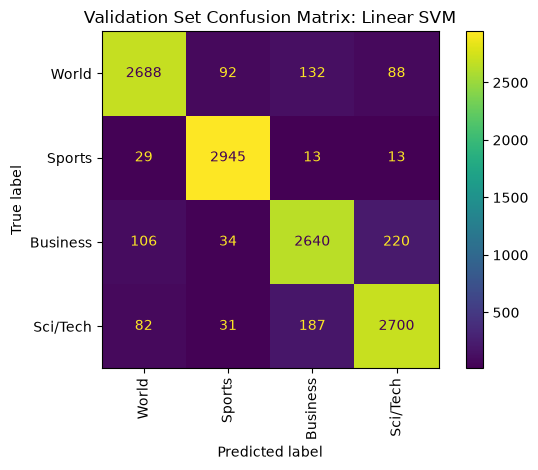

Classification Report on the Test Set:
              precision    recall  f1-score   support

       World       0.93      0.90      0.91      1900
      Sports       0.95      0.98      0.97      1900
    Business       0.87      0.87      0.87      1900
    Sci/Tech       0.88      0.88      0.88      1900

    accuracy                           0.91      7600
   macro avg       0.91      0.91      0.91      7600
weighted avg       0.91      0.91      0.91      7600



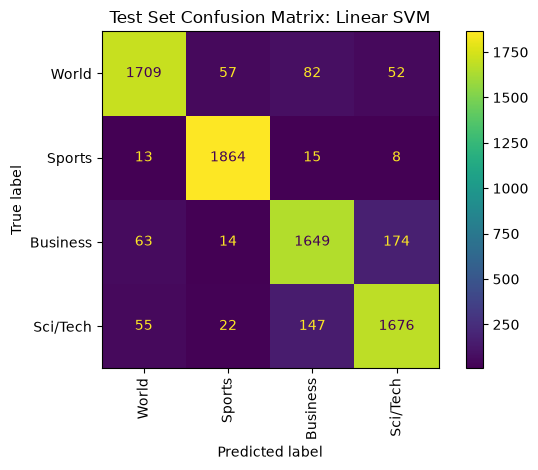

In [18]:
param_grid_svm = {"C": [0.1, 1], "loss": ["hinge", "squared_hinge"]}

best_model, best_macrof1, best_params = grid_search_svm(
    param_grid_svm, X_train, y_train, X_val, y_val
)

print(f"Best model: {best_model}")
print(f"Best Macro-F1: {best_macrof1:.4f}")
print(f"Best found parameters: {best_params}")

eval_model(best_model, X_val, y_val, "Validation")
eval_model(best_model, X_test, y_test, "Test")